<a href="https://colab.research.google.com/github/Adrien-Rouillon/Machine-learning---SpotifyDB/blob/main/Notebooks/Delivrable2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MOD10 – Deliverable 2 : exploration and pre-processing data
**Membres du groupe :** Adrien ROUILLON, Paul MORAND

**Data set :** Spotify

---

In [23]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os, glob
import pandas as pd

FILENAME = "spotify_artist_streaming_2020_2025.csv"

candidates = [FILENAME, f"/content/{FILENAME}"] + glob.glob(f"/content/drive/**/{FILENAME}", recursive=True)
path = next((p for p in candidates if os.path.exists(p)), None)

if path is None:
    from google.colab import files
    print("File not found. Please select", FILENAME)
    files.upload()
    path = FILENAME

df = pd.read_csv(path)
print("Loaded:", path, df.shape)

File not found. Please select spotify_artist_streaming_2020_2025.csv


KeyboardInterrupt: 

Before we need to do any data analysis, we need to mess it up since we chose a perfect dataset.

We gave the prompt from class 2 notebook into Claude. It generated us a "add_noise" function to make the data less clean.

In [ ]:
def add_noise(df, seed=42):  # return a messy copy of a clean DataFrame
    rng = np.random.default_rng(seed)  # fixed seed -> same mess every run
    out = df.copy(deep=True)  # work on a deep copy so df is never modified
    num_cols = out.select_dtypes("number").columns.tolist()  # numeric columns available to corrupt
    if len(num_cols) < 2:  # need at least two numeric columns
        raise ValueError("df needs at least 2 numeric columns")  # fail loudly instead of guessing
    miss_cols = num_cols[:2]  # first two numeric columns get missing values
    out_col = num_cols[0]  # first numeric column gets outliers
    text_col = num_cols[2] if len(num_cols) > 2 else num_cols[1]  # third (or second) becomes text
    n = len(out)  # number of original rows

    # --- extreme outliers ---
    out_idx = rng.choice(out.index, size=3, replace=False)  # pick 3 rows to corrupt
    col = out[out_col].astype(float)  # float copy so large values fit
    col.loc[out_idx] = col.mean() + 20 * col.std() * rng.choice([-1, 1], size=3)  # push Â±20 std from the mean
    out[out_col] = col  # write outliers back

    # --- ~5% missing values in two numeric columns ---
    for c in miss_cols:  # handle each target column
        nan_idx = rng.choice(out.index, size=max(1, round(0.05 * n)), replace=False)  # 5% random rows
        out[c] = out[c].astype(float)  # ints can't hold NaN, so cast to float
        out.loc[nan_idx, c] = np.nan  # blank them out

    # --- inconsistent categorical column ---
    base = rng.choice(["Red", "Green", "Blue"], size=n)  # clean underlying categories
    variants = [str.lower, str.upper, str.title, lambda s: f" {s}", lambda s: f"{s}  "]  # case/spacing styles
    out["color"] = [variants[rng.integers(len(variants))](v) for v in base]  # apply a random style per row

    # --- numeric column stored as text with a stray 'unknown' ---
    out[text_col] = out[text_col].map(lambda v: "" if pd.isna(v) else str(v)).astype(object)  # numbers -> strings
    out.loc[rng.choice(out.index), text_col] = "unknown"  # one non-numeric token

    # --- 5 exact duplicate rows ---
    dup_rows = out.loc[rng.choice(out.index, size=5, replace=False)]  # copy 5 existing (already messy) rows
    out = pd.concat([out, dup_rows], ignore_index=True)  # append them -> exact duplicates
    out = out.sample(frac=1, random_state=seed).reset_index(drop=True)  # shuffle so dupes aren't at the end

    return out  # the messy copy

df = add_noise(df)

## Étape 1 – Exploration (EDA)



---



In [ ]:
df.head()

,track_id,track_name,artist_name,album_name,release_date,genre,duration_ms,popularity,danceability,energy,...,loudness_category,key_name,mode_name,is_explicit_bool,release_quarter,is_weekend_release,log_stream_count,upbeat_score,artist_track_count,color
0,1c22dd2a-4646-47a1-b354-2fc81b05088a,Electric Fire,Ethereal,The Broken Stories,2020-05-31,Pop,178551.0,33.0,0.6422,0.6088,...,Moderate,C#,Major,True,Q2,True,9.7061,0.6007,3232,GREEN
1,991b08a9-b94a-4a87-a397-6b547bfa2626,Golden Mirrors,IsleEyre,Endless Keys,2022-10-14,Pop,NaN,17.0,0.6503,0.5237,...,Moderate,G#,Major,False,Q4,False,7.9659,0.5485,5271,Blue
2,2939f47b-f4e1-4ce1-bcce-47382fae8b38,Walking Echoes,IsleEyre,Tapes,2022-05-10,Pop,226433.0,24.0,0.5826,0.8425,...,Moderate,D#,Minor,False,Q2,False,10.2064,0.6179,5271,Red
3,0fb1ce22-3de6-432f-97fd-cb20d2dc175a,Paper Gentle Shadows,IsleEyre,Burning Wings,2020-11-29,Soul,204174.0,26.0,0.5797,0.4981,...,Moderate,D#,Minor,False,Q4,True,9.7636,0.5348,5271,BLUE
4,3b11fe9f-0067-4c90-8723-79be21855941,Heavy Shadows,Knot Hart,Fading Lights,2021-08-17,R&B,202885.0,17.0,0.7227,0.3697,...,Moderate,E,Minor,True,Q3,False,9.1829,0.5097,12111,blue


In [ ]:
df.shape

(50005, 34)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50005 entries, 0 to 50004
Data columns (total 34 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   track_id             50005 non-null  object 
 1   track_name           50005 non-null  object 
 2   artist_name          50005 non-null  object 
 3   album_name           50005 non-null  object 
 4   release_date         50005 non-null  object 
 5   genre                50005 non-null  object 
 6   duration_ms          47505 non-null  float64
 7   popularity           47505 non-null  float64
 8   danceability         50005 non-null  object 
 9   energy               50005 non-null  float64
 10  key                  50005 non-null  int64  
 11  loudness             50005 non-null  float64
 12  mode                 50005 non-null  int64  
 13  instrumentalness     50005 non-null  float64
 14  tempo                50005 non-null  float64
 15  stream_count         50005 non-null 

In [ ]:
df.describe()

,duration_ms,popularity,energy,key,loudness,mode,instrumentalness,tempo,stream_count,release_year,release_month,duration_minutes,log_stream_count,upbeat_score,artist_track_count
count,4.750500e+04,47505.000000,50005.000000,50005.000000,50005.000000,50005.000000,50005.000000,50005.000000,5.000500e+04,50005.00000,50005.000000,50005.000000,50005.000000,50005.000000,50005.000000
mean,2.098441e+05,28.124050,0.631860,5.471113,-7.669432,0.650315,0.055161,119.069178,1.183838e+05,2022.49973,6.528947,3.496884,9.835547,0.601621,4052.428997
std,4.515745e+04,16.008085,0.168744,3.456205,2.621857,0.476875,0.095079,19.652739,5.658199e+05,1.70991,3.460836,0.744114,1.793925,0.105078,4817.982759
min,-6.831059e+05,0.000000,0.000000,0.000000,-18.620000,0.000000,0.000000,60.000000,1.000000e+02,2020.00000,1.000000,1.500000,4.615100,0.057800,2.000000
25%,1.798030e+05,16.000000,0.523400,2.000000,-9.440000,0.000000,0.010300,105.990000,4.980000e+03,2021.00000,4.000000,3.000000,8.513400,0.542100,181.000000
50%,2.097220e+05,26.000000,0.633400,5.000000,-7.660000,1.000000,0.025700,118.580000,1.595400e+04,2023.00000,7.000000,3.490000,9.677500,0.606400,1486.000000
75%,2.396770e+05,39.000000,0.744700,8.000000,-5.880000,1.000000,0.057600,131.350000,6.069000e+04,2024.00000,10.000000,4.000000,11.013600,0.671100,5271.000000
max,1.102735e+06,92.000000,1.000000,11.000000,0.000000,1.000000,1.000000,220.000000,4.334502e+07,2025.00000,12.000000,6.470000,17.584700,0.915400,12111.000000


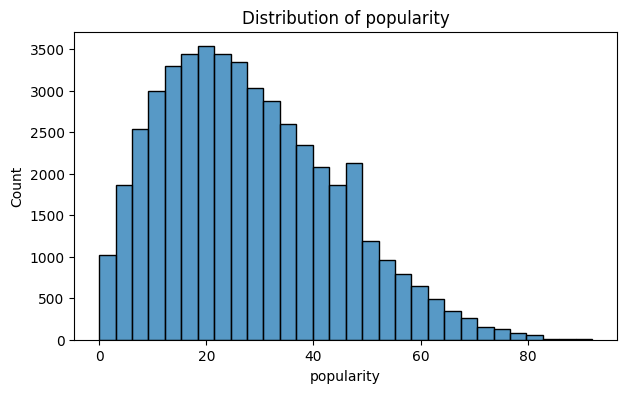

,popularity
log_stream_count,0.894113
stream_count,0.406650
key,0.006308
release_month,-0.004888
mode,-0.001868
instrumentalness,-0.001715
release_year,0.001569
upbeat_score,0.001552
loudness,0.001496
artist_track_count,-0.001465


In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(df["popularity"].dropna(), bins=30)
plt.title("Distribution of popularity")
plt.show()

corr = df.select_dtypes(include="number").corr()["popularity"].drop("popularity").sort_values(key=abs, ascending=False)
corr.head(10)



---



**Observation:**

- The dataset contains 50,005 rows and 34 columns.
- `.info()` shows that `duration_ms` and `popularity` have 2,500 missing values each. These are the problems introduced by `add_noise`.
- `.describe()` reveals an impossible value: `duration_ms` has a minimum of -683,105 and a maximum of 1,102,735.
- Popularity The histogram show that most of the most part of track are not popular.
- Several columns are redundant (`duration_minutes`, `key_name`, `mode_name`...) or derived from the target (`popularity_category`).

## Étape 2 – Missing values



---



In [ ]:
df.isna().sum()

,0
track_id,0
track_name,0
artist_name,0
album_name,0
release_date,0
genre,0
duration_ms,2500
popularity,2500
danceability,0
energy,0


**Observation:**

.isna() : Returns us the table with either True or False depending if the cell is empty or not.

.sum() : Counts each True in a column.

In [ ]:
# 1. Droping duplicates value
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# 2. Droping values that miss in popularity
df = df.dropna(subset=["popularity"])

# 3. Droping incoherent values in duration_ms
df = df[df["duration_ms"].isna() | df["duration_ms"].between(30_000, 900_000)]

# 4. Filling missing values with the median
df["duration_ms"] = df["duration_ms"].fillna(df["duration_ms"].median())

# 5. Conversion in number and suppresion of "unknown"
df["danceability"] = pd.to_numeric(df["danceability"], errors="coerce")
df = df.dropna(subset=["danceability"])

print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("popularity max:", df["popularity"].max())

Duplicates: 5
(47497, 34)
Missing values: 0
popularity max: 92.0


**What we did and why**

- **Duplicates**: 5 exact duplicate rows were removed, because the same track counted twice would bias the model.
- **`popularity` (2,500 missing)**: rows dropped. It is our target, so a row without it cannot teach the model anything, and filling it with a median would invent fake answers.
- **`duration_ms` outliers**: rows with a duration below 30 seconds or above 15 minutes (including negative values) were removed, as they are impossible or extreme values introduced by the noise.
- **`duration_ms` (missing)**: filled with the median, which is not affected by extreme values, unlike the mean. Dropping these rows would have cost 5 % of the data.
- **`danceability`**: converted to a number; the single "unknown" value was dropped.
- **Mistake we avoided**: filling all columns with the median of `duration_ms` would have written durations into `popularity`, so each column is handled separately.

## Étape 3 – Encoding



---



<style>
  table {
    table-layout: fixed;
    width: 100%;
  }
  table th, table td {
    word-wrap: break-word;
    overflow-wrap: break-word;
    padding: 10px 12px !important;
  }
</style>

<table>
  <thead>
    <tr>
      <th style="width: 30%;">Columns</th>
      <th style="width: 25%;">Decision</th>
      <th style="width: 45%;">Why</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>track_name<br>album_name<br>artist_name<br>release_date</td>
      <td>Removed</td>
      <td>Almost a unique value per row, so nothing to learn. release_year and release_month already carry the date info.</td>
    </tr>
    <tr>
      <td>popularity_category</td>
      <td>Removed</td>
      <td>It is derived from popularity, your target. Keeping it would be cheating (data leakage).</td>
    </tr>
    <tr>
      <td>duration_minutes<br>key_name<br>mode_name<br>is_explicit_bool<br>loudness_category<br>release_quarter<br>log_stream_count</td>
      <td>Removed</td>
      <td>Duplicates of columns already present. I keep stream_count; you can take log_stream_count instead, but not both.</td>
    </tr>
    <tr>
      <td>explicit<br>is_weekend_release</td>
      <td>bool &rarr; 0/1</td>
      <td>Already binary.</td>
    </tr>
    <tr>
      <td>mode</td>
      <td>Nothing to do</td>
      <td>Already in 0/1.</td>
    </tr>
    <tr>
      <td>key<br>genre<br>country<br>release_day_of_week<br>label</td>
      <td>One-hot (get_dummies)</td>
      <td>Unordered categories.</td>
    </tr>
  </tbody>
</table>

In [ ]:
for c in df.select_dtypes(include="object").columns:
    print(f"{c:22s} {df[c].nunique():>6} unique values")
#Generated code by AI to see unique values we have to treat.

track_id                47497 unique values
track_name               8656 unique values
artist_name               500 unique values
album_name               4017 unique values
release_date             2192 unique values
genre                      20 unique values
country                    30 unique values
label                      30 unique values
release_day_of_week         7 unique values
popularity_category         4 unique values
loudness_category           3 unique values
key_name                   12 unique values
mode_name                   2 unique values
release_quarter             4 unique values
color                      15 unique values


In [ ]:
#This is all the columns we didn't need.

to_drop = [
    "track_name", "album_name", "artist_name", "release_date",              #text with unique value
    "popularity_category",                                                  #Leak : popularity drift
    "duration_minutes", "key_name", "mode_name", "is_explicit_bool",
    "loudness_category", "release_quarter", "log_stream_count",             #doubles
    "index", "track_id","color"
]

df = df.drop(columns=[c for c in to_drop if c in df.columns])
df.head()

,genre,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,country,explicit,label,release_year,release_month,release_day_of_week,is_weekend_release,upbeat_score,artist_track_count
0,Pop,178551.0,33.0,0.6422,0.6088,1,-9.76,1,0.0020,130.24,16416,KR,True,Cipher Music,2020,5,Sunday,True,0.6007,3232
1,Pop,209647.0,17.0,0.6503,0.5237,8,-6.02,1,0.0653,115.25,2880,BR,False,Cipher Music,2022,10,Friday,False,0.5485,5271
2,Pop,226433.0,24.0,0.5826,0.8425,3,-6.02,0,0.0832,93.51,27074,DE,False,Independent,2022,5,Tuesday,False,0.6179,5271
3,Soul,204174.0,26.0,0.5797,0.4981,3,-11.41,0,0.0194,132.61,17388,KR,False,Columbia Records,2020,11,Sunday,True,0.5348,5271
4,R&B,202885.0,17.0,0.7227,0.3697,4,-10.87,0,0.0023,110.94,9728,US,True,Self-Released,2021,8,Tuesday,False,0.5097,12111


In [ ]:
bool_map = {True:1,False:0,"true":1,"false":0,"True":1,"False":0}
df['explicit'] = df['explicit'].map(bool_map)
df['is_weekend_release'] = df['is_weekend_release'].map(bool_map)

df.head()

,genre,duration_ms,popularity,danceability,energy,key,loudness,mode,instrumentalness,tempo,stream_count,country,explicit,label,release_year,release_month,release_day_of_week,is_weekend_release,upbeat_score,artist_track_count
0,Pop,178551.0,33.0,0.6422,0.6088,1,-9.76,1,0.0020,130.24,16416,KR,1,Cipher Music,2020,5,Sunday,1,0.6007,3232
1,Pop,209647.0,17.0,0.6503,0.5237,8,-6.02,1,0.0653,115.25,2880,BR,0,Cipher Music,2022,10,Friday,0,0.5485,5271
2,Pop,226433.0,24.0,0.5826,0.8425,3,-6.02,0,0.0832,93.51,27074,DE,0,Independent,2022,5,Tuesday,0,0.6179,5271
3,Soul,204174.0,26.0,0.5797,0.4981,3,-11.41,0,0.0194,132.61,17388,KR,0,Columbia Records,2020,11,Sunday,1,0.5348,5271
4,R&B,202885.0,17.0,0.7227,0.3697,4,-10.87,0,0.0023,110.94,9728,US,1,Self-Released,2021,8,Tuesday,0,0.5097,12111


In [ ]:
#Apply to lower case
for c in ["genre", "country", "release_day_of_week", "label"]:
    df[c] = df[c].map(str.lower)

#Regrouping unique type of label in other
top_labels = set(df["label"].value_counts().nlargest(10).index)
df["label"] = df["label"].map(lambda x: x if x in top_labels else "other")

#Adding precision on key
df["key"] = df["key"].map(lambda x: f"key_{x}")

#Making data readable by IA
df = pd.get_dummies(df, columns=["key", "genre", "country", "release_day_of_week", "label"],
                    drop_first=True, dtype=int)

print(df.shape)
print("None numerics columns :", list(df.select_dtypes(exclude="number").columns))
print("Missing values :", df.isna().sum().sum())
df.head()



(47497, 90)
None numerics columns : []
Missing values : 0


,duration_ms,popularity,danceability,energy,loudness,mode,instrumentalness,tempo,stream_count,explicit,...,label_catalyst records,label_cipher music,label_horizon records,label_independent,label_indie collective,label_neon label,label_other,label_prism audio,label_stardust label,label_wavelength records
0,178551.0,33.0,0.6422,0.6088,-9.76,1,0.0020,130.24,16416,1,...,0,1,0,0,0,0,0,0,0,0
1,209647.0,17.0,0.6503,0.5237,-6.02,1,0.0653,115.25,2880,0,...,0,1,0,0,0,0,0,0,0,0
2,226433.0,24.0,0.5826,0.8425,-6.02,0,0.0832,93.51,27074,0,...,0,0,0,1,0,0,0,0,0,0
3,204174.0,26.0,0.5797,0.4981,-11.41,0,0.0194,132.61,17388,0,...,0,0,0,0,0,0,1,0,0,0
4,202885.0,17.0,0.7227,0.3697,-10.87,0,0.0023,110.94,9728,1,...,0,0,0,0,0,0,1,0,0,0


**Decisions**

- **Dropped columns**: `track_id`, `track_name`, `album_name`, `artist_name`, `release_date` (almost one unique value per row, so there is nothing to generalise; the date is already in `release_year` and `release_month`).
- **`popularity_category`** was removed because it is computed from `popularity` (data leakage).
- **Duplicates removed**: `duration_minutes`, `key_name`, `mode_name`, `is_explicit_bool`, `loudness_category`, `release_quarter`, `log_stream_count` carry the same information as other columns.
- **`color`** was dropped: it is a column added by the noise function and has no link with music.
- **`explicit` and `is_weekend_release`**: converted to 0/1 with `map()` because they are binary.
- **`mode`** is already 0/1.
- **`genre`, `country`, `label`, `release_day_of_week`, `key`**: one-hot encoding with `get_dummies()` because these categories have no order. We keep `key` as a category because note 8 is not "greater" than note 3.
- **`label`**: 30 labels would have created 30 columns, so only the 10 most frequent are kept and the others are grouped as "other".
- **`drop_first=True`** removes one redundant column per category.
- The dataset goes from 33 columns to about 90 numeric columns.

## Étape 4 – Train / Test Split



---



In [ ]:
print(df["popularity"].quantile([0.5, 0.75, 0.9, 0.94, 0.95]))

0.50    26.0
0.75    39.0
0.90    50.0
0.94    56.0
0.95    58.0
Name: popularity, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

SEUIL = 50

y = (df["popularity"] >= SEUIL).astype(int)
X = df.drop(columns=["popularity"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print("Part of hits train/test :", y_train.mean().round(3), y_test.mean().round(3))

(37997, 89) (9500, 89)
Part of hits train/test : 0.011 0.011


We split before scaling so that the scaler is fitted on the training set only, which avoids data leakage (see step 5). This reverses the order of the instructions' list, on purpose.

- **Target**: a track is a "hit" (1) if `popularity` ≥ 50, which is the 90th percentile, so a hit is a track in the top 10 %. This turns question 1 into a classification problem. We chose 50 rather than 70 because a threshold of 70 gave only 1.1 % of hits, which is too few examples for a model to learn from.
- `popularity` is removed from the features, otherwise the model could read the answer directly.
- **80 % train / 20 % test**: 37,997 / 9,500 tracks. `random_state=42` makes the split reproducible.

## Étape 5 – Scaling



---



All the columns have differents types of scales (duration_ms ≈ 200 000, danceability ≈ 0,6).

So we will standardize them with StandarScaler : (value − moyen) / écart-type

In [ ]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["duration_ms", "danceability", "energy", "loudness", "instrumentalness",
              "tempo", "stream_count", "release_year", "release_month", "upbeat_score"]

X_train[scale_cols].describe().loc[["mean", "std"]].round(2)

,duration_ms,danceability,energy,loudness,instrumentalness,tempo,stream_count,release_year,release_month,upbeat_score
mean,209802.66,0.66,0.63,-7.67,0.05,119.13,117077.79,2022.50,6.53,0.6
std,43538.16,0.16,0.17,2.62,0.09,19.66,509877.64,1.71,3.46,0.1


In [ ]:
scaler = StandardScaler()

In [ ]:
X_train = X_train.copy()
X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

X_train[scale_cols].describe().loc[["mean", "std"]].round(2)

,duration_ms,danceability,energy,loudness,instrumentalness,tempo,stream_count,release_year,release_month,upbeat_score
mean,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [ ]:
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
print("Colonnes non numériques :", X_train.select_dtypes(exclude="number").columns.tolist())

Colonnes non numériques : []


Features are on very different scales: `duration_ms` is around 210,000 while `danceability` is around 0.6 and `stream_count` goes up to 43 million. Models based on distances or weights would give far too much importance to the large values.

We standardize the continuous columns with `StandardScaler`: (value − mean) / standard deviation, so each column has a mean of 0 and a standard deviation of 1.

- Binary columns (0/1) from the encoding are not scaled, they are already on a comparable scale.
- The target `popularity` is not scaled.
- The scaler is fitted on the training set only (step 5) to avoid data leakage.

## Étape 6 – Short reflection



---



**Main decisions**: dropping rows without popularity rather than filling them, median for durations, removal of impossible durations, one-hot encoding of unordered categories, grouping rare labels, inversing order of scaling and train/test split.

**What surprised us**: We first applied the scaling before the train/test split, as shown in the course. But then, IA show us that create a data leakage: the mean and standard deviation were computed on all the rows, test set included, so the test data was no longer completely "unseen". We therefore swapped the order: we split first, then fitted the scaler on `X_train` only and applied it to `X_test`.

We were also surprised that filling the whole DataFrame with one median silently corrupted our target (`popularity`), which we noticed because the 95th quantile was equal to the maximum value.

**Limits**: `stream_count` is probably a consequence of popularity rather than a cause, and the noisy data were artificially generated.